In [192]:
from scipy import stats

In [193]:
import matplotlib.pyplot as plt

In [194]:
import duckdb
con = duckdb.connect("data/flights.duckdb")

## **Delay and Cancellation Rate by Airline Name**

In [195]:
by_name = con.execute('''SELECT carrier_name, COUNT(*) AS num_flights, AVG(delayed) AS
     avg_delay_rate, AVG(cancelled) AS cancellation_rate FROM fact_flights f LEFT JOIN dim_carrier c ON f.carrier_code = c.carrier_code
     GROUP BY carrier_name ORDER BY avg_delay_rate DESC''').df()
display(by_name)
assert(by_name['num_flights'].sum() == 7043858)



,carrier_name,num_flights,avg_delay_rate,cancellation_rate
0,JetBlue Airways,237090,0.269698,0.030558
1,Spirit Air Lines,117136,0.265603,0.039390
2,Frontier Airlines Inc.,209405,0.262201,0.019226
3,Allegiant Air,126499,0.253253,0.006593
4,PSA Airlines Inc.,242215,0.252507,0.042904
5,American Airlines Inc.,987645,0.247469,0.021971
6,Southwest Airlines Co.,1389951,0.227284,0.008805
7,Republic Airline,363168,0.207302,0.041333
8,SkyWest Airlines Inc.,854130,0.203930,0.017826
9,United Air Lines Inc.,825693,0.200620,0.010306


JetBlue Airways still bodes the highest average delay rate and top 4 in cancellation rate. If you take a combination of both of them into account you may say that Spirit Air Lines or PSA Airlines inc.

## **Delay and Cancellation Rate by Season**

In [196]:
by_season = con.execute('''SELECT season, COUNT(*) AS num_flights, AVG(delayed) AS
     avg_delay_rate, AVG(cancelled) AS cancellation_rate FROM fact_flights LEFT JOIN dim_date ON flight_date = date
     GROUP BY season ORDER BY avg_delay_rate DESC''').df()
display(by_season)
assert(by_season['num_flights'].sum() == 7043858)

,season,num_flights,avg_delay_rate,cancellation_rate
0,Summer,1841925,0.248522,0.017933
1,Winter,1641344,0.219111,0.028173
2,Spring,1821756,0.212856,0.015822
3,Fall,1738833,0.185555,0.011666


Summer had the highest delay rate at 25%, Fall the lowest at 19%.

## **Delay and Cancellation Rate by Holiday**

In [197]:
by_holiday = con.execute('''SELECT is_holiday, COUNT(*) AS num_flights, AVG(delayed) AS
     avg_delay_rate, AVG(cancelled) AS cancellation_rate FROM fact_flights LEFT JOIN dim_date ON flight_date = date
     GROUP BY is_holiday ORDER BY avg_delay_rate DESC''').df()
display(by_holiday)
assert(by_holiday['num_flights'].sum() == 7043858)

,is_holiday,num_flights,avg_delay_rate,cancellation_rate
0,True,204296,0.233288,0.020544
1,False,6839562,0.216334,0.018157


## T-Test
Run a welch's t-test with an assumed alpha of 0.05, to compare the average delay rates on holidays and non-holidays and determine if there is sufficient evidence of a higher average delay rate.

,is_holiday,date,num_flights,avg_delay_rate,cancellation_rate
0,False,2026-03-16,20678,0.544892,0.195715
1,False,2025-11-30,21576,0.458937,0.038515
2,False,2025-11-09,20442,0.444314,0.121319
3,False,2026-01-25,18675,0.424972,0.464846
4,False,2026-01-26,18042,0.408387,0.271201
...,...,...,...,...,...
360,False,2026-01-12,17857,0.085737,0.001344
361,False,2025-11-15,16675,0.083049,0.013733
362,True,2025-11-27,11001,0.070719,0.001454
363,False,2025-09-30,17514,0.069289,0.000514


,is_holiday,date,num_flights,avg_delay_rate,cancellation_rate
19,True,2026-06-19,21143,0.358393,0.057513
61,True,2025-10-13,21028,0.282401,0.013553
66,True,2026-07-03,20393,0.278899,0.035600
68,True,2026-01-01,17388,0.277535,0.010007
86,True,2026-02-16,20060,0.263851,0.011565
105,True,2026-05-25,20946,0.245752,0.014848
110,True,2026-01-19,18876,0.241644,0.005828
256,True,2025-09-01,20157,0.170957,0.004663
295,True,2025-11-11,17867,0.152149,0.052723
340,True,2025-12-25,15437,0.119271,0.005895


Number of holidays: 11 
Average Delay Rate: 0.22377927692107302


,is_holiday,date,num_flights,avg_delay_rate,cancellation_rate
0,False,2026-03-16,20678,0.544892,0.195715
1,False,2025-11-30,21576,0.458937,0.038515
2,False,2025-11-09,20442,0.444314,0.121319
3,False,2026-01-25,18675,0.424972,0.464846
4,False,2026-01-26,18042,0.408387,0.271201
...,...,...,...,...,...
359,False,2026-02-10,16469,0.086298,0.000850
360,False,2026-01-12,17857,0.085737,0.001344
361,False,2025-11-15,16675,0.083049,0.013733
363,False,2025-09-30,17514,0.069289,0.000514


Number of non-holidays: 354 
Average Delay Rate: 0.21536333901416457


Results of Welch's t-test
Test Statistic: 0.3246186620969528 P-value: 0.751846671052311


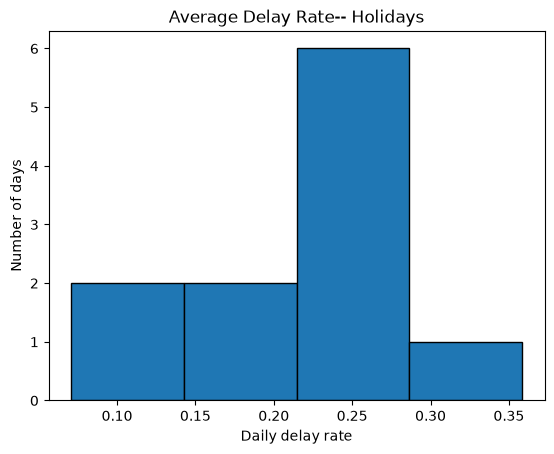

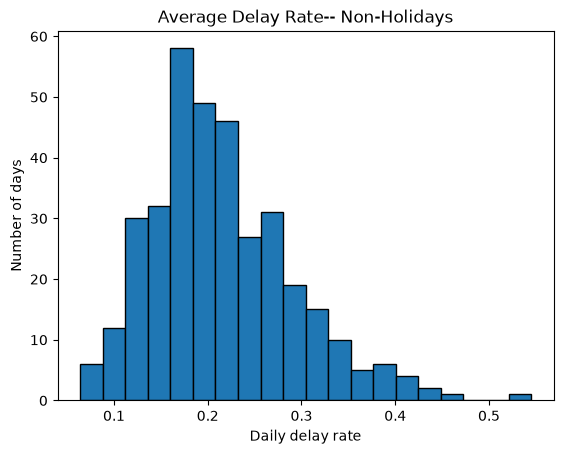

In [198]:
by_holiday_date = con.execute('''SELECT is_holiday, date, COUNT(*) AS num_flights, AVG(delayed) AS
     avg_delay_rate, AVG(cancelled) AS cancellation_rate FROM fact_flights LEFT JOIN dim_date ON flight_date = date
     GROUP BY is_holiday, date ORDER BY avg_delay_rate DESC''').df()
display(by_holiday_date)
holidays = by_holiday_date[by_holiday_date["is_holiday"] == True]
display(holidays)
print("Number of holidays:", holidays["is_holiday"].sum(), "\nAverage Delay Rate:", holidays["avg_delay_rate"].mean())
non_holidays = by_holiday_date[by_holiday_date["is_holiday"] == False]
display(non_holidays)
print("Number of non-holidays:", (non_holidays["is_holiday"] == False).sum(), "\nAverage Delay Rate:", non_holidays["avg_delay_rate"].mean())

## Run the test now
res_welch = stats.ttest_ind(holidays["avg_delay_rate"], non_holidays["avg_delay_rate"], equal_var=False)

print("\n\nResults of Welch's t-test\nTest Statistic:", res_welch.statistic, "P-value:", res_welch.pvalue)
plt.hist(holidays["avg_delay_rate"], bins=4, edgecolor='black')
plt.title("Average Delay Rate-- Holidays")
plt.xlabel("Daily delay rate")
plt.ylabel("Number of days")
plt.show()
plt.hist(non_holidays["avg_delay_rate"], bins=20, edgecolor='black')
plt.title("Average Delay Rate-- Non-Holidays")
plt.xlabel("Daily delay rate")
plt.ylabel("Number of days")
plt.show()



**Hypotheses:** H₀: mean daily delay rate is the same on holidays and regular days. Hₐ: they differ. α = 0.05.

**Result:** Welch's t = 0.32, p = 0.75. Since 0.75 > 0.05, fail to reject H₀. There is not sufficient evidence that the average delay rate on holidays differs from regular days.

**Note on the means:** these differ from Query #3 because #3 averaged every flight together, so busy days counted more. Here, each day's rate is computed first, then days are averaged, so every day counts equally.

**Summary:** Across 11 holidays and 354 regular days, holiday daily delay rates were not significantly different from regular days. Given the small number of holidays and their uneven spread across seasons, this result means no difference was detected, not that holidays have no effect on delays.

## **Delay and Cancellation Rate by Routes**

In [199]:
by_route = con.execute('''SELECT o.city AS origin_city, d.city AS destination_city, origin_airport, dest_airport, COUNT(*) AS num_flights, AVG(delayed) AS
     avg_delay_rate, AVG(cancelled) AS cancellation_rate FROM fact_flights f LEFT JOIN dim_airport o ON f.origin_airport = o.airport_code
     LEFT JOIN dim_airport d ON f.dest_airport = d.airport_code GROUP BY o.city, d.city, origin_airport, dest_airport HAVING num_flights >= 365 ORDER BY avg_delay_rate DESC LIMIT 10''').df()
print(con.execute(''' SELECT AVG(delayed) FROM fact_flights''').df())
display(by_route)

   avg(delayed)
0      0.216824


,origin_city,destination_city,origin_airport,dest_airport,num_flights,avg_delay_rate,cancellation_rate
0,Chicago,San Francisco,MDW,SFO,485,0.506276,0.012371
1,Knoxville,Fort Lauderdale,TYS,FLL,481,0.446089,0.008316
2,Dallas/Fort Worth,Harrisburg,DFW,MDT,365,0.426554,0.030137
3,Chicago,Eagle,ORD,EGE,413,0.416244,0.036320
4,Philadelphia,Washington,PHL,DCA,789,0.403718,0.043093
5,Dallas,Charlotte,DAL,CLT,377,0.403226,0.010610
6,Fort Lauderdale,Asheville,FLL,AVL,659,0.401235,0.010622
7,Dallas/Fort Worth,Buffalo,DFW,BUF,578,0.399287,0.029412
8,San Luis Obispo,San Francisco,SBP,SFO,1145,0.392920,0.012227
9,Arcata/Eureka,San Francisco,ACV,SFO,1292,0.390088,0.029412


In [200]:
import time

In [201]:
import numpy as np

## Does adding a shortcut make my queries faster?
We will be checking if using a database index helps find rows faster.

In [202]:
con.execute('''DROP INDEX IF EXISTS idx_route''')
# Starts the timer
times = []
for i in range(10):
    start = time.perf_counter()
    by_route = con.execute('''SELECT o.city AS origin_city, d.city AS destination_city, origin_airport, dest_airport, COUNT(*) AS num_flights, AVG(delayed) AS
        avg_delay_rate, AVG(cancelled) AS cancellation_rate FROM fact_flights f LEFT JOIN dim_airport o ON f.origin_airport = o.airport_code
        LEFT JOIN dim_airport d ON f.dest_airport = d.airport_code GROUP BY o.city, d.city, origin_airport, dest_airport HAVING num_flights >= 365 ORDER BY avg_delay_rate DESC LIMIT 10''').df()
    times.append(time.perf_counter() - start) #time.perf_counter returns end time here
print("Median Elapsed Time Pre-Index:", np.median(times))



Median Elapsed Time Pre-Index: 0.16795844997977838


#### Create the Index

In [203]:
con.execute('''CREATE INDEX idx_route ON fact_flights(origin_airport, dest_airport)''')

In [204]:
times = []
for i in range(10):
    start = time.perf_counter()
    by_route = con.execute('''SELECT o.city AS origin_city, d.city AS destination_city, origin_airport, dest_airport, COUNT(*) AS num_flights, AVG(delayed) AS
        avg_delay_rate, AVG(cancelled) AS cancellation_rate FROM fact_flights f LEFT JOIN dim_airport o ON f.origin_airport = o.airport_code
        LEFT JOIN dim_airport d ON f.dest_airport = d.airport_code GROUP BY o.city, d.city, origin_airport, dest_airport HAVING num_flights >= 365 ORDER BY avg_delay_rate DESC LIMIT 10''').df()
    times.append(time.perf_counter() - start) #time.perf_counter returns end time here
print("Median Elapsed Time Post-Index:", np.median(times))

Median Elapsed Time Post-Index: 0.15973429998848587


This tests whether the index helps a query that returns only a few rows (one singular route) out of 7 million, which is the case indexes are designed for.

In [205]:
con.execute('''DROP INDEX IF EXISTS idx_route''')
times = []
for i in range(10):
    start = time.perf_counter()
    con.execute('''SELECT * FROM fact_flights WHERE origin_airport = 'MDW' AND dest_airport = 'SFO' ''').df()
    times.append(time.perf_counter() - start) #time.perf_counter returns end time here
print("Median Elapsed Time Pre-Index:", np.median(times))

Median Elapsed Time Pre-Index: 0.023417600023094565


In [206]:
con.execute('''CREATE INDEX idx_route ON fact_flights(origin_airport, dest_airport)''')

In [207]:
times = []
for i in range(10):
    start = time.perf_counter()
    con.execute('''SELECT * FROM fact_flights WHERE origin_airport = 'MDW' AND dest_airport = 'SFO' ''').df()
    times.append(time.perf_counter() - start) #time.perf_counter returns end time here
print("Median Elapsed Time Post-Index:", np.median(times))

Median Elapsed Time Post-Index: 0.023387549998005852


In [208]:
con.execute('''DROP INDEX IF EXISTS idx_route''')

## Index test results

| Query | Before index (s) | After index (s) |
|---|---|---|
| Routes (all 7M rows, grouped) | 0.168 | 0.160 |
| Lookup (MDW → SFO only, ~485 rows) | 0.023 | 0.023 |

Times are the median of 10 runs each.

**Conclusion:** The index on `(origin_airport, dest_airport)` gave no meaningful speedup for either query. The routes query reads every row, so an index has nothing to skip. Even the lookup query, the case indexes are designed for, didn't improve, because DuckDB already skips irrelevant chunks